##### Feladat (Példatár 2.9)

A feszültségi tenzor mátrixa egy anyagi pontban az $x$-$y$-$z$ koordináta rendszerben ismert. Határozzuk meg a főfeszültségeket és a feszültségi főirányokat sajátérték és sajátvektor számítással! Ábrázoljuk a feszültségi állapotot a Mohr körök segítségével!

<img src="img/01.jpg" alt="Feladat" width=250px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
# Feszültségi tenzor az x-y-z koordináta rendszerben
sigma = sp.Matrix([[90, 40,   0],
                   [40, 30,   0],
                   [ 0,  0, -50]]) # MPa
display(Math(rf'\boldsymbol{{\sigma}}_{{(x,y,z)}} = {latex(sigma)} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

#### a) Főfeszültségek meghatározása sajátérték számítással

$$\left( \boldsymbol{\sigma} - \sigma \cdot \mathbf{I} \right) \cdot \mathbf{n} = \mathbf{0} \qquad \longrightarrow \qquad \det \left( \boldsymbol{\sigma} - \sigma \cdot \mathbf{I} \right) = 0$$

ahol:
- $\boldsymbol{\sigma}$: a feszültségi tenzor,
- $\sigma$: a főfeszültség (sajátérték),
- $\mathbf{I}$: az egységtenzor,
- $\mathbf{n}$: a feszültségi főirány (sajátvektor).

A jobb oldali egyenlet a karakterisztikus egyenlet.

##### Karakterisztikus egyenlet

In [3]:
s = sp.Symbol('sigma') # Ismeretlen főfeszültség
I = sp.eye(3) # Egységtenzor

display(Math(rf'\boldsymbol{{\sigma}} - \sigma \cdot \mathbf{{I}} = {latex(sigma - s*I)}'))

# Determináns kifejtése
char_eq = (sigma - s*I).det()
display(Math(rf'\det \left( \boldsymbol{{\sigma}} - \sigma \cdot \mathbf{{I}} \right) = {latex(sp.factor(char_eq))} = 0'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Főfeszültségek

In [4]:
# A karakterisztikus egyenlet gyökei (a többszörös gyököket is beleértve)
sol = sp.roots(char_eq, s, multiple=True)

# Sorbarendezés után: σ_1 >= σ_2 >= σ_3
sigma_1, sigma_2, sigma_3 = sorted(sol, reverse=True)

display(Math(rf'\sigma_1 = {latex(round(sigma_1, 2))} ~\mathrm{{MPa}}'))
display(Math(rf'\sigma_2 = {latex(round(sigma_2, 2))} ~\mathrm{{MPa}}'))
display(Math(rf'\sigma_3 = {latex(round(sigma_3, 2))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

#### b) Feszültségi főirányok meghatározása sajátvektor számítással

Vegyük észre, hogy $\sigma_3 = \sigma_z = -50 ~\mathrm{MPa}$, mivel $\tau_{xz} = \tau_{yz} = 0$! Tehát a $\sigma_3$-hoz tartozó $\mathbf{k}$ irány főirány!

In [5]:
n_3 = sp.Matrix([0, 0, 1])
display(Math(rf'\mathbf{{n}}_3 = \mathbf{{k}} = {latex(n_3)}'))

<IPython.core.display.Math object>

##### A másik 2 főirány az $x$-$y$ síkban

<img src="img/02.jpg" alt="Feladat" width=200px>

In [6]:
phi = sp.Symbol('varphi')

n_1 = sp.Matrix([sp.cos(phi), sp.sin(phi), 0])
display(Math(rf'\mathbf{{n}}_1 = {latex(n_1)}'))

n_2 = n_3.cross(n_1)
display(Math(rf'\mathbf{{n}}_2 = \mathbf{{n}}_3 \times \mathbf{{n}}_1 = {latex(n_2)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Például $\sigma_1$ esetén

In [7]:
eq = (sigma - sigma_1*I) * n_1
display(Math(rf'\left( \boldsymbol{{\sigma}} - \sigma_1 \cdot \mathbf{{I}} \right) \cdot \mathbf{{n}}_1 = {latex(sigma - sigma_1*I)} {latex(n_1)} = \mathbf{{0}}'))

<IPython.core.display.Math object>

In [8]:
# Kifejezve az 1. sort
display(Math(rf'{latex(eq[0])} = 0'))

# cos(φ)-vel leosztva tg(φ)-re rendezhető
m = - eq[0].coeff(sp.cos(phi)) / eq[0].coeff(sp.sin(phi))
display(Math(rf'\mathrm{{tg}}(\varphi) = {latex(m)}'))

eq = sp.tan(phi) - m
sol = sp.solve(eq, phi)
phi_sol = sol[0]
display(Math(rf'\varphi = {latex(round(sp.deg(phi_sol), 2))}^\circ'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<img src="img/03.jpg" alt="Feladat" width=200px>

##### Így a főirányok

In [9]:
n_1 = n_1.subs(phi, phi_sol)
n_2 = n_2.subs(phi, phi_sol)

display(Math(rf'\mathbf{{n}}_1 = {latex(n_1.evalf(3))}, \quad \mathbf{{n}}_2 = {latex(n_2.evalf(3))}, \quad \mathbf{{n}}_3 = {latex(n_3)}'))

<IPython.core.display.Math object>

##### Ellenőrzés beépített függvénnyel

In [10]:
# Szimmetrikus mátrix sajátértékei és sajátvektorai (növekvő sorrendben)
sajatertekek, sajatvektorok = np.linalg.eigh(np.array(sigma, dtype=float))

# Sorbarendezés csökkenő sorrendbe
sajatertekek = sajatertekek[::-1]
sajatvektorok = sajatvektorok[:, ::-1]

display(Math(rf'\left[ \sigma_1 ~ \sigma_2 ~ \sigma_3 \right] = {latex(sp.Matrix(np.round(sajatertekek, 3) + 0.0).T)} ~\mathrm{{MPa}}'))
display(Math(rf'\left[ \mathbf{{n}}_1 ~ \mathbf{{n}}_2 ~ \mathbf{{n}}_3 \right] = {latex(sp.Matrix(np.round(sajatvektorok, 3) + 0.0))}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

A sajátvektorok előjele tetszőleges, hiszen $\mathbf{n}$ és $-\mathbf{n}$ ugyanazt a főirányt jelöli.

#### c) Ábrázolás Mohr körökkel

Csak akkor tudjuk megcsinálni, ha az egyik főfeszültség ismert!

##### A tenzorból

In [11]:
sigma_x = sigma[0, 0]
sigma_y = sigma[1, 1]
sigma_z = sigma[2, 2] # főfeszültség
tau_xy = sigma[0, 1]

display(Math(rf'\sigma_x = {latex(sigma_x)} ~\mathrm{{MPa}}'))
display(Math(rf'\tau_{{xy}} = {latex(tau_xy)} ~\mathrm{{MPa}}'))
display(Math(rf'\sigma_y = {latex(sigma_y)} ~\mathrm{{MPa}}'))
display(Math(rf'\sigma_z = {latex(sigma_z)} ~\mathrm{{MPa}} ~ \text{{(főfeszültség)}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### 1. Pontok felvétele a nem ismert feszültségi síkba ($x$-$y$)

In [12]:
X = (sigma_x, sp.Abs(tau_xy))
Y = (sigma_y, sp.Abs(tau_xy))
Z = (sigma_z, 0)

display(Math(rf'X(\sigma_x, |\tau_{{xy}}|) = X{latex(X)}'))
display(Math(rf'Y(\sigma_y, |\tau_{{xy}}|) = Y{latex(Y)}'))
display(Math(rf'Z(\sigma_z, 0) = Z{latex(Z)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### 2. Mohr kör középpontja és sugara

In [13]:
sigma_K = (sigma_x + sigma_y) / 2
display(Math(rf'\sigma_K = \frac{{\sigma_x + \sigma_y}}{{2}} = {latex(round(sigma_K, 2))} ~\mathrm{{MPa}}'))

R = sp.sqrt(((sigma_x - sigma_y) / 2)**2 + tau_xy**2)
display(Math(rf'R = \sqrt{{\left( \frac{{\sigma_x - \sigma_y}}{{2}} \right)^2 + \tau_{{xy}}^2}} = {latex(round(R, 2))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### 3. Rajzoljuk meg az $X$ és $Y$ pontokon átmenő kört és határozzuk meg a főfeszültségeket

In [14]:
sigma_1 = sigma_K + R
display(Math(rf'\sigma_1 = \sigma_K + R = {latex(round(sigma_1, 2))} ~\mathrm{{MPa}}'))

sigma_2 = sigma_K - R
display(Math(rf'\sigma_2 = \sigma_K - R = {latex(round(sigma_2, 2))} ~\mathrm{{MPa}}'))

sigma_3 = sigma_z
display(Math(rf'\sigma_3 = \sigma_z = {latex(round(sigma_3, 2))} ~\mathrm{{MPa}}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

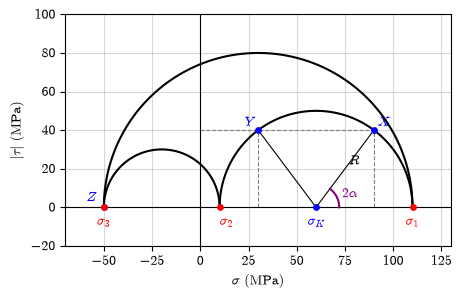

In [15]:
# Mohr körök középpontjai és sugarai a főfeszültségekből
s_1, s_2, s_3 = float(sigma_1), float(sigma_2), float(sigma_3)
s_K, R_num = float(sigma_K), float(R)
X_num = [float(X[0]), float(X[1])]
Y_num = [float(Y[0]), float(Y[1])]
Z_num = [float(Z[0]), float(Z[1])]

t = np.linspace(0, np.pi, 200)

plt.figure(figsize=(12/2.54, 8/2.54))

# Mohr körök (felső félkörök, mivel |τ|-t ábrázolunk)
plt.plot((s_1 + s_2)/2 + (s_1 - s_2)/2*np.cos(t), (s_1 - s_2)/2*np.sin(t), color='black', zorder=4)
plt.plot((s_2 + s_3)/2 + (s_2 - s_3)/2*np.cos(t), (s_2 - s_3)/2*np.sin(t), color='black', zorder=4)
plt.plot((s_1 + s_3)/2 + (s_1 - s_3)/2*np.cos(t), (s_1 - s_3)/2*np.sin(t), color='black', zorder=4)

# X és Y pontok összekötése a kör középpontjával
plt.plot([X_num[0], s_K, Y_num[0]], [X_num[1], 0, Y_num[1]], color='black', linewidth=0.8, zorder=4)
plt.plot([0, X_num[0]], [X_num[1], X_num[1]], '--', color='gray', linewidth=0.8)
plt.plot([X_num[0], X_num[0]], [0, X_num[1]], '--', color='gray', linewidth=0.8)
plt.plot([Y_num[0], Y_num[0]], [0, Y_num[1]], '--', color='gray', linewidth=0.8)

# 2α szög jelölése
two_alpha = np.arctan2(X_num[1], X_num[0] - s_K)
t_alpha = np.linspace(0, two_alpha, 50)
plt.plot(s_K + 12*np.cos(t_alpha), 12*np.sin(t_alpha), color='purple', zorder=5)
plt.text(s_K + 15*np.cos(two_alpha/2), 15*np.sin(two_alpha/2), r'$2\alpha$', color='purple', va='center')

# Pontok
plt.scatter([X_num[0], Y_num[0], Z_num[0], s_K], [X_num[1], Y_num[1], Z_num[1], 0], color='blue', s=15, zorder=6)
plt.scatter([s_1, s_2, s_3], [0, 0, 0], color='red', s=15, zorder=6)

# Feliratok
plt.text(X_num[0] + 2, X_num[1] + 2, r'$X$', color='blue')
plt.text(Y_num[0] - 7, Y_num[1] + 2, r'$Y$', color='blue')
plt.text(Z_num[0] - 9, Z_num[1] + 3, r'$Z$', color='blue')
plt.text(s_K, -4, r'$\sigma_K$', color='blue', ha='center', va='top')
plt.text(s_1, -4, r'$\sigma_1$', color='red', ha='center', va='top')
plt.text(s_2, -4, r'$\sigma_2$', color='red', ha='left', va='top')
plt.text(s_3, -4, r'$\sigma_3$', color='red', ha='center', va='top')
plt.text((s_K + X_num[0])/2 + 2, X_num[1]/2 + 2, r'$R$')

plt.axhline(0, color='black', linewidth=0.8)
plt.axvline(0, color='black', linewidth=0.8)
plt.xlabel(r'$\sigma ~ \mathrm{(MPa)}$')
plt.ylabel(r'$|\tau| ~ \mathrm{(MPa)}$')
plt.grid(True, alpha=0.5)
plt.gca().set_aspect('equal')
plt.xlim(-70, 130)
plt.ylim(-20, 100)
plt.tight_layout()
plt.savefig('mohr_korok.pdf')
plt.show()

##### 4. Az $\alpha$ szög számítása

In [16]:
alpha = 1/2 * sp.atan(2*sp.Abs(tau_xy) / (sigma_x - sigma_y))
display(Math(rf'\alpha = \frac{{1}}{{2}} \arctan \left( \frac{{2|\tau_{{xy}}|}}{{\sigma_x - \sigma_y}} \right) = {latex(round(sp.deg(alpha), 2))}^\circ'))

<IPython.core.display.Math object>

##### 5. Sajátvektorok

<img src="img/04.jpg" alt="Feladat" width=300px>

- Ránézünk az $x$-$y$ síkra, felrajzoljuk a feszültségi kiskockát.
- Azt a tengelyt ($x$ vagy $y$) forgatjuk, amelyiknek pontja közelebb van a nagyobb főfeszültséghez $\rightarrow$ $x$ tengely!
- Forgatás iránya: $\tau_{xy}$ iránya.

In [17]:
a = sp.Symbol('alpha')

n_1 = sp.Matrix([sp.cos(a), sp.sin(a), 0])
display(Math(rf'\mathbf{{n}}_1 = {latex(n_1)} = {latex(n_1.subs(a, alpha).evalf(3))}'))

n_2 = sp.Matrix([-sp.sin(a), sp.cos(a), 0])
display(Math(rf'\mathbf{{n}}_2 = {latex(n_2)} = {latex(n_2.subs(a, alpha).evalf(3))}'))

n_3 = sp.Matrix([0, 0, 1])
display(Math(rf'\mathbf{{n}}_3 = \mathbf{{k}} = {latex(n_3)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Az eredmények megegyeznek a sajátvektor számítással kapott főirányokkal.